Download the SDSS quasar data

- Upsample this distribution in hopefully two ways (but at least one of them), using both rejection sampling and inverse transform.
- Check, at least visually, that the two cloned distribitions are indeed similar to the observed one (for a quantitative check, come back to this point in a few lectures)
- Think about the cosmology of quasars. How do you think they are distributed? Overplot the theorethical distribution to the measured SDSS data. Does that agree with your expectation? 

(Hint: It shouldn't. But why?) 

In [ ]:
### This used to work, but now it's broken...
"""
from astroML.datasets import fetch_dr7_quasar

# Fetch the quasar data
data = fetch_dr7_quasar()

# select the first 10000 points
data = data[:10000]

z = data['redshift']
"""


In [60]:
import os
import numpy as np
import matplotlib.pyplot as plt
import astropy

In [64]:
from urllib.request import urlretrieve
filename = '../solutions/dr7qso.dat'
if not os.path.exists(filename):
   urlretrieve("https://das.sdss.org/va/qsocat/dr7qso.dat", filename)


Text(0.5, 0, 'z')

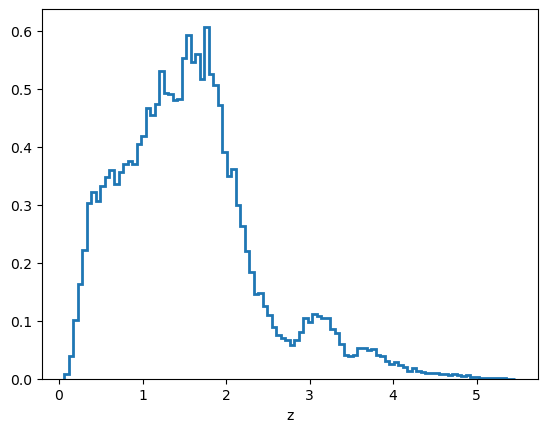

In [65]:
z= np.loadtxt(filename,skiprows=80, usecols=3)

plt.hist(z,bins=100,density=True,histtype='step',lw=2)
plt.xlabel('z')

In [66]:
counts , edges = np.histogram(z, bins=100, density = True)

print(z.min(),z.max(),counts.max())


0.0645 5.4608 0.6068284284408393


0.3054 0.6068184472206936 0.6068284284408393


<function matplotlib.pyplot.show(close=None, block=None)>

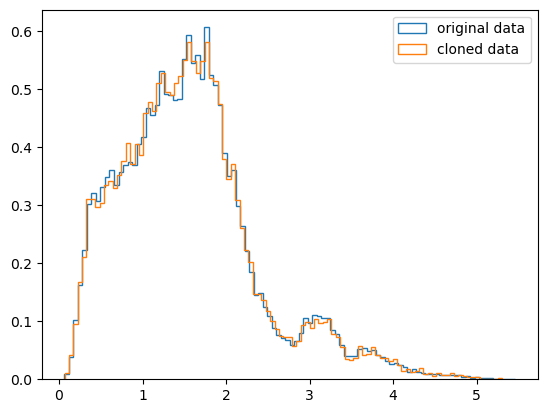

In [67]:
N = 100000

ymax = counts.max()
x = np.random.uniform(z.min(),z.max(),N)
y = np.random.uniform(0,ymax,N)

index = np.digitize(x,edges) -1 #digitize start counting from 1 while counts starts from 0 
high = counts[index] 

accepted = y < high

plt.hist(z,bins=100, histtype='step', density=True, label='original data')
plt.hist(x[accepted], bins=100, histtype='step', density=True, label='cloned data')

print(accepted.mean(), y.max(), ymax) # ymax() has to be smaller than ymax or equal first is the max of the generated second is the upper bound
plt.legend()
plt.show



1.0


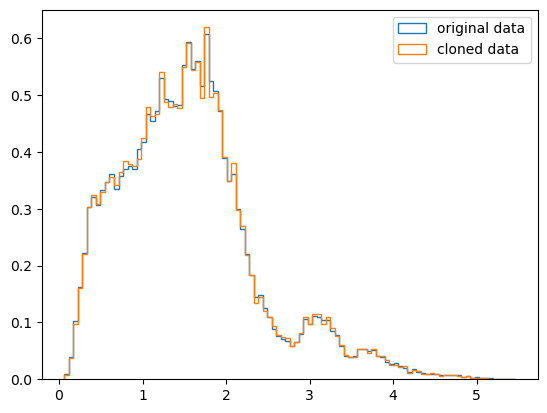

In [68]:
values = np.sort(z)
n = len(values)

n_new = 100000

cdf = np.arange(1,n+1)/n  

u = np.random.uniform(0,1,n_new)

indices = np.searchsorted(cdf,u)

z_u = values[indices]

print(cdf[-1])

plt.hist(z,bins=100, histtype='step', density=True, label='original data')
plt.hist(z_u,bins=100, histtype='step', density=True, label='cloned data')

plt.legend()
plt.show()

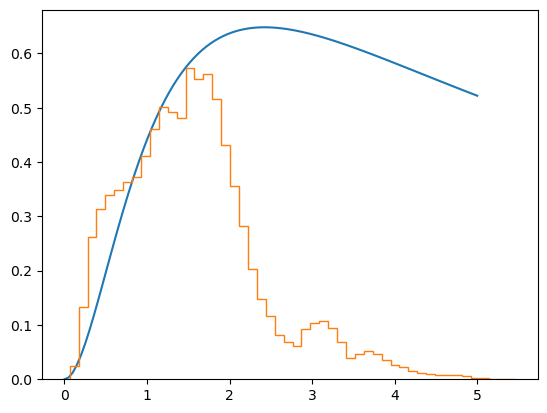

In [69]:
astropy.cosmology.Planck18
z_vals = np.linspace(0,5,100)
comvol = astropy.cosmology.Planck18.differential_comoving_volume(z_vals).value

z_lin = np.linspace(0,5,100)
plt.plot(z_lin,comvol/6.5e10) ###   Arbitrary normalization, just matching by eye

plt.hist(z,bins=50,histtype='step',density=True,label='original data');